# SLM Testing

In [2]:
from pytweezer.drivers.slm import SLM
import pytweezer.phasemask as pm
import numpy as np
import matplotlib.pyplot as plt
from pytweezer.drivers.thorcam import ThorCamera

In [3]:
slm : SLM = SLM()

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.462 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\slm40_at852.LUT"


In [13]:
slm.close()

SLM 1 closed.


In [4]:
blank = np.zeros((1024, 1024), dtype=np.uint8)
slm.update_mask(blank)

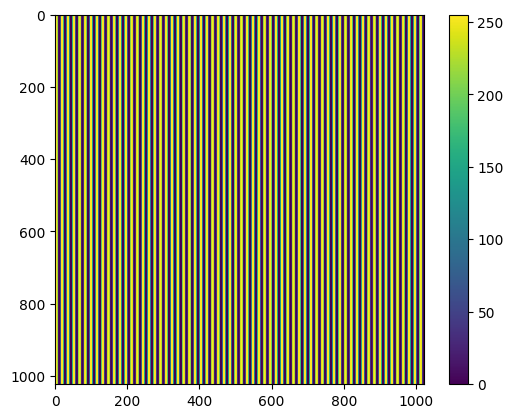

In [7]:
grating = binary_grating(16, 0)
plt.imshow(grating)
plt.colorbar()

In [8]:
slm.update_mask(grating)

---

In [ ]:
thorcam : ThorCamera = ThorCamera(id="tweezercam")
thorcam.set_exposure_time(0.000001)
thorcam.set_trigger_source("int")

Thorlabs TLCamera - tweezercam - initialised.


In [62]:
thorcam.set_exposure_time(0.000001)
thorcam.set_trigger_source("int")

In [52]:
thorcam.setup_acquisition(nframes=2)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=2)

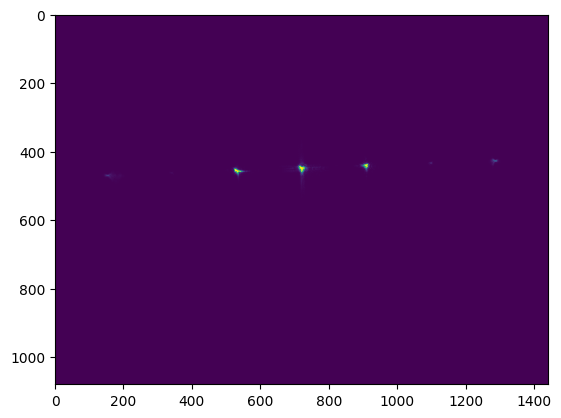

In [53]:
plt.imshow(imgs.mean(axis=0))

---

In [183]:
thorcam : ThorCamera = ThorCamera(id="tweezercam")
thorcam.set_exposure_time(0.000001)
thorcam.set_trigger_source("int")

Thorlabs TLCamera - tweezercam - initialised.


In [181]:
thorcam.close()

In [196]:
slm.close()

SLM 1 closed.


In [197]:
slm : SLM = SLM(lut_file="C:\\Program Files\\Meadowlark Optics\\Blink Plus\\LUT Files\\1024x1024_linearVoltage.lut")

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.462 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\1024x1024_linearVoltage.lut"


In [224]:
thorcam.set_exposure_time(0.001)

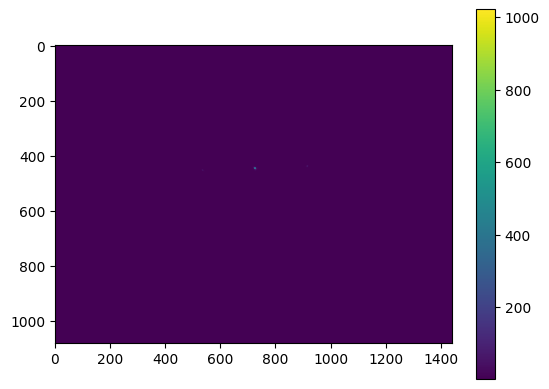

In [232]:
grating = binary_grating(16, 150)
slm.update_mask(grating)
thorcam.setup_acquisition(nframes=5)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=5)
img_mean = imgs.mean(axis=0)

plt.imshow(img_mean)
plt.colorbar()

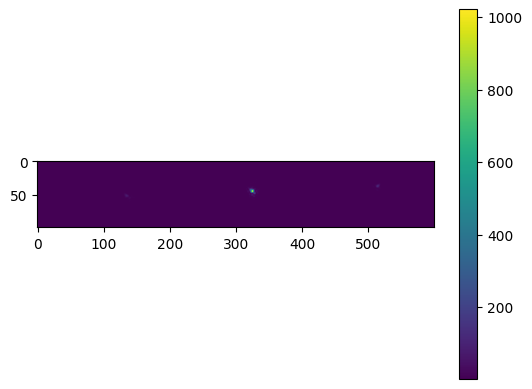

In [233]:
plt.imshow(img_mean[400:500, 400:1000])
plt.colorbar()

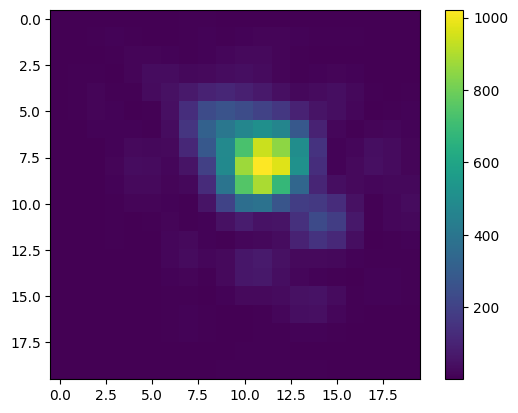

In [234]:
y0 = 448
x0 = 724
window = 20
plt.imshow(img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2])
plt.colorbar()

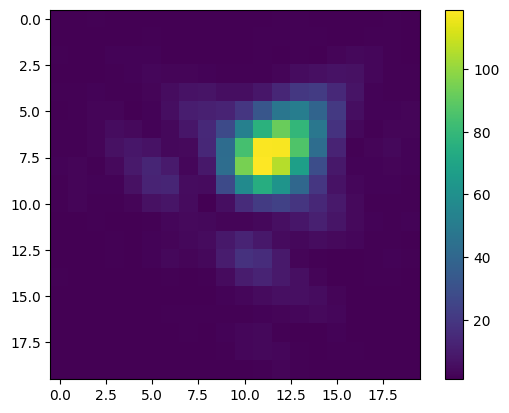

In [235]:
y1 = 441
x1 = 913
window = 20
plt.imshow(img_mean[y1-window//2:y1+window//2, x1-window//2:x1+window//2])
plt.colorbar()

In [236]:
import time

depths = np.arange(256, dtype=np.uint8)[::-1]
i0_array = []
i1_array = []

for depth in depths:
    grating = binary_grating(16, depth)
    slm.update_mask(grating)
    time.sleep(1.0)
    thorcam.setup_acquisition(nframes=10)
    thorcam.start_acquisition()
    imgs = thorcam.acquire_n_frames(nframes=10)
    img_mean = imgs.mean(axis=0)

    i0 = img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2].sum()
    i1 = img_mean[y1-window//2:y1+window//2, x1-window//2:x1+window//2].sum()

    i0_array.append(i0)
    i1_array.append(i1)

    print(f"Grating Depth: {depth} | 0th order: {i0:.1f} | 1st order: {i1:.1f}")

Grating Depth: 255 | 0th order: 46687.1 | 1st order: 420.2
Grating Depth: 254 | 0th order: 49699.6 | 1st order: 419.1
Grating Depth: 253 | 0th order: 49216.7 | 1st order: 420.1
Grating Depth: 252 | 0th order: 52292.6 | 1st order: 417.8
Grating Depth: 251 | 0th order: 51052.0 | 1st order: 419.6
Grating Depth: 250 | 0th order: 51090.0 | 1st order: 417.4
Grating Depth: 249 | 0th order: 53985.4 | 1st order: 419.9
Grating Depth: 248 | 0th order: 48485.5 | 1st order: 417.6
Grating Depth: 247 | 0th order: 50733.8 | 1st order: 414.8
Grating Depth: 246 | 0th order: 51939.0 | 1st order: 417.7
Grating Depth: 245 | 0th order: 50398.4 | 1st order: 420.7
Grating Depth: 244 | 0th order: 50708.5 | 1st order: 421.3
Grating Depth: 243 | 0th order: 50006.8 | 1st order: 424.3
Grating Depth: 242 | 0th order: 50285.2 | 1st order: 428.8
Grating Depth: 241 | 0th order: 50061.9 | 1st order: 427.1
Grating Depth: 240 | 0th order: 47766.8 | 1st order: 433.9
Grating Depth: 239 | 0th order: 49431.3 | 1st order: 437

Text(0, 0.5, 'Normalised Intensity')

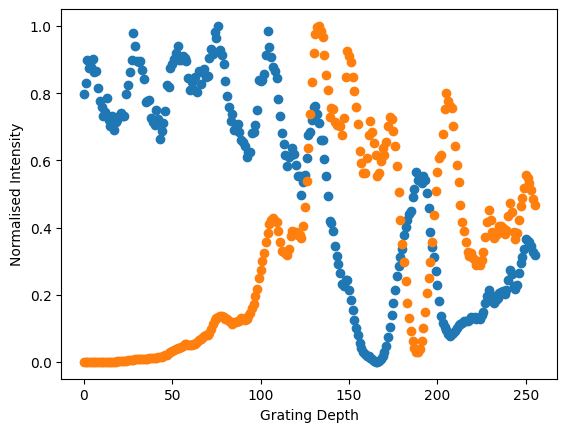

In [230]:
i0_array = np.array(i0_array)
i1_array = np.array(i1_array)

i0_array_norm = normalise(i0_array)
i1_array_norm = normalise(i1_array)

plt.scatter(depths[::-1], i0_array_norm)
plt.scatter(depths[::-1], i1_array_norm)
plt.xlabel("Grating Depth")
plt.ylabel("Normalised Intensity")

Text(0, 0.5, 'Normalised Intensity')

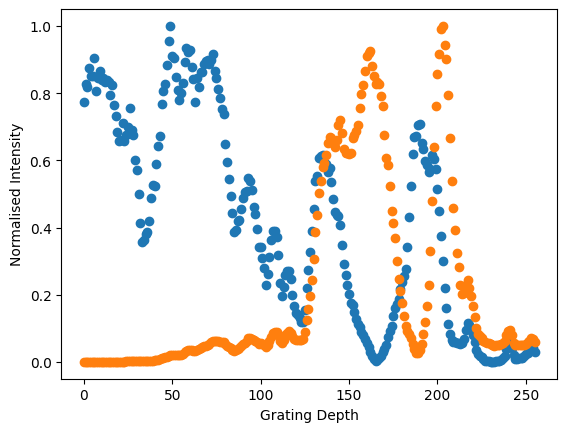

In [237]:
i0_array = np.array(i0_array)
i1_array = np.array(i1_array)

i0_array_norm = normalise(i0_array)
i1_array_norm = normalise(i1_array)

plt.scatter(depths[::-1], i0_array_norm)
plt.scatter(depths[::-1], i1_array_norm)
plt.xlabel("Grating Depth")
plt.ylabel("Normalised Intensity")

In [149]:
import numpy as np
import pandas as pd

# grey: 8-bit grey levels (0-255); intensity: normalised intensity (0-1), same length
df = pd.DataFrame({"grey_level": np.asarray(depths[::-1], dtype=np.uint8),
                   "norm_intensity": np.asarray(i1_array_norm, dtype=float)})
df.to_csv("C:\\Program Files\\Meadowlark Optics\\Blink Plus\\Cal Kit\\Raw0.csv", index=False, float_format="%.6g")

In [238]:
thorcam.close()
slm.close()

Thorlabs TLCamera - tweezercam - closed.
SLM 1 closed.


---
## Calibration Script

In [2]:
import numpy as np

def binary_grating(period, height, shape=(1024, 1024)):
    """Binary grating alternating between a fixed reference level (255) and `height` (0-255).
    period in pixels. Returns a uint8 array of `shape` (rows, cols)."""
    x = np.arange(shape[1])
    row = np.where((x % period) < period / 2, 255, height).astype(np.uint8)
    return np.tile(row, (shape[0], 1))

def normalise(a):
    """Linearly rescale array `a` so its minimum maps to 0 and its maximum to 1."""
    a = np.asarray(a, dtype=float)
    lo, hi = a.min(), a.max()
    if hi == lo:                      # constant array: avoid divide-by-zero
        return np.zeros_like(a)
    return (a - lo) / (hi - lo)

In [3]:
thorcam : ThorCamera = ThorCamera(id="tweezercam")

Thorlabs TLCamera - tweezercam - initialised.


In [13]:
y0 = 448
x0 = 724

y1 = 391
x1 = 863

window = 100

thorcam.set_exposure_time(0.0005)
thorcam.set_trigger_source("int")
thorcam.set_roi(x1, window, y1, window)

In [5]:
slm : SLM = SLM(lut_file="C:\\Program Files\\Meadowlark Optics\\Blink Plus\\LUT Files\\1024x1024_linearVoltage.lut")

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.462 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\1024x1024_linearVoltage.lut"


In [23]:
import time

depths = np.arange(256, dtype=np.uint8)[::-1]

for depth in depths:
    grating = binary_grating(16, depth)
    slm.update_mask(grating)
    time.sleep(0.2)

    print(f"Grating Depth: {depth}")

Grating Depth: 255
Grating Depth: 254
Grating Depth: 253
Grating Depth: 252
Grating Depth: 251
Grating Depth: 250
Grating Depth: 249
Grating Depth: 248
Grating Depth: 247
Grating Depth: 246
Grating Depth: 245
Grating Depth: 244
Grating Depth: 243
Grating Depth: 242
Grating Depth: 241
Grating Depth: 240
Grating Depth: 239
Grating Depth: 238
Grating Depth: 237
Grating Depth: 236
Grating Depth: 235
Grating Depth: 234
Grating Depth: 233
Grating Depth: 232
Grating Depth: 231
Grating Depth: 230
Grating Depth: 229
Grating Depth: 228
Grating Depth: 227
Grating Depth: 226
Grating Depth: 225
Grating Depth: 224
Grating Depth: 223
Grating Depth: 222
Grating Depth: 221
Grating Depth: 220
Grating Depth: 219
Grating Depth: 218
Grating Depth: 217
Grating Depth: 216
Grating Depth: 215
Grating Depth: 214
Grating Depth: 213
Grating Depth: 212
Grating Depth: 211
Grating Depth: 210
Grating Depth: 209
Grating Depth: 208
Grating Depth: 207
Grating Depth: 206
Grating Depth: 205
Grating Depth: 204
Grating Dept

In [6]:
grating = binary_grating(16, 80)
slm.update_mask(grating)

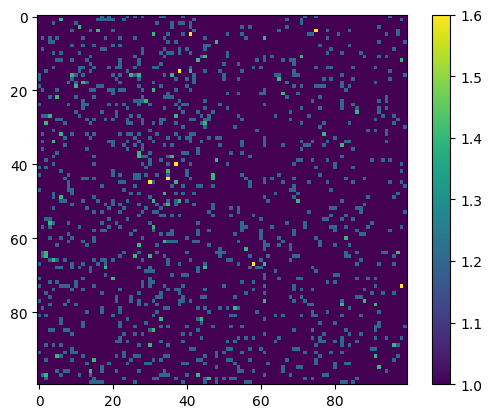

In [16]:
thorcam.setup_acquisition(nframes=5)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=5)
bg_mean = imgs.mean(axis=0)

plt.imshow(bg_mean)
plt.colorbar()

In [17]:
grating = binary_grating(16, 80)
slm.update_mask(grating)

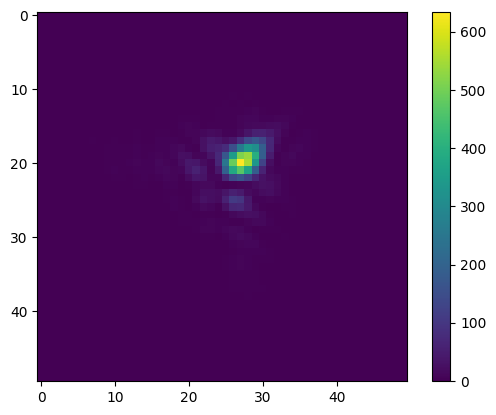

In [19]:
crop = 50

thorcam.setup_acquisition(nframes=5)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=5)
img_mean = imgs.mean(axis=0) - bg_mean

plt.imshow(img_mean[50-crop//2:50+crop//2, 50-crop//2:50+crop//2])
plt.colorbar()

In [20]:
import time

depths = np.arange(256, dtype=np.uint8)[::-1]
I0_list = []

for depth in depths:
    grating = binary_grating(16, depth)
    slm.update_mask(grating)
    time.sleep(0.1)
    thorcam.setup_acquisition(nframes=1)
    thorcam.start_acquisition()
    imgs = thorcam.acquire_n_frames(nframes=1)
    img_mean = imgs.mean(axis=0) - bg_mean
    I0 = img_mean[50-crop//2:50+crop//2, 50-crop//2:50+crop//2].sum()
    I0_list.append(I0)

    print(f"Secondary Gray Value: {depth} | Depth: {255-depth} | Intensity: {I0:.1f}")

Secondary Gray Value: 255 | Depth: 0 | Intensity: 15.8
Secondary Gray Value: 254 | Depth: 1 | Intensity: 18.8
Secondary Gray Value: 253 | Depth: 2 | Intensity: 45.8
Secondary Gray Value: 252 | Depth: 3 | Intensity: 14.8
Secondary Gray Value: 251 | Depth: 4 | Intensity: 13.8
Secondary Gray Value: 250 | Depth: 5 | Intensity: 17.8
Secondary Gray Value: 249 | Depth: 6 | Intensity: 26.8
Secondary Gray Value: 248 | Depth: 7 | Intensity: 17.8
Secondary Gray Value: 247 | Depth: 8 | Intensity: 9.8
Secondary Gray Value: 246 | Depth: 9 | Intensity: 29.8
Secondary Gray Value: 245 | Depth: 10 | Intensity: 30.8
Secondary Gray Value: 244 | Depth: 11 | Intensity: 18.8
Secondary Gray Value: 243 | Depth: 12 | Intensity: 46.8
Secondary Gray Value: 242 | Depth: 13 | Intensity: 24.8
Secondary Gray Value: 241 | Depth: 14 | Intensity: 31.8
Secondary Gray Value: 240 | Depth: 15 | Intensity: 41.8
Secondary Gray Value: 239 | Depth: 16 | Intensity: 52.8
Secondary Gray Value: 238 | Depth: 17 | Intensity: 76.8
Sec

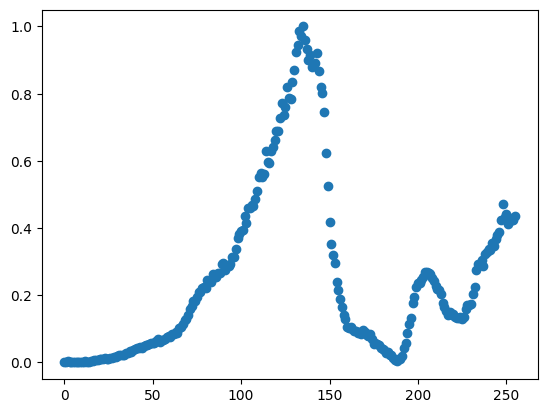

In [21]:
plt.scatter(depths[::-1], normalise(I0_list))

In [22]:
slm.close()

SLM 1 closed.


In [23]:
slm.close()

In [24]:
thorcam.close()

Thorlabs TLCamera - tweezercam - closed.


---

## Second Calibration Attempt

In [64]:
from pytweezer.drivers.slm import SLM
import pytweezer.phasemask as pm
import numpy as np
import matplotlib.pyplot as plt
from pytweezer.drivers.thorcam import ThorCamera

def binary_grating(period, height, shape=(1024, 1024)):
    """Binary grating alternating between a fixed reference level (255) and `height` (0-255).
    period in pixels. Returns a uint8 array of `shape` (rows, cols)."""
    x = np.arange(shape[1])
    row = np.where((x % period) < period / 2, 255, height).astype(np.uint8)
    return np.tile(row, (shape[0], 1))

def normalise(a):
    """Linearly rescale array `a` so its minimum maps to 0 and its maximum to 1."""
    a = np.asarray(a, dtype=float)
    lo, hi = a.min(), a.max()
    if hi == lo:                      # constant array: avoid divide-by-zero
        return np.zeros_like(a)
    return (a - lo) / (hi - lo)

In [ ]:

slm : SLM = SLM(lut_file="C:\\Program Files\\Meadowlark Optics\\Blink Plus\\LUT Files\\1024x1024_linearVoltage.lut")

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.929 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\1024x1024_linearVoltage.lut"


In [65]:
thorcam : ThorCamera = ThorCamera(id="tweezercam")

Thorlabs TLCamera - tweezercam - initialised.


In [66]:
thorcam.set_exposure_time(0.005)
thorcam.set_trigger_source("int")

In [67]:
grating = binary_grating(16, 80)
slm.update_mask(grating)

#### Find 0th and 1st order spots

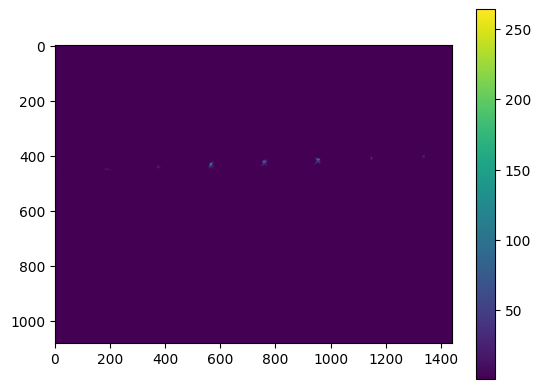

In [68]:
thorcam.setup_acquisition(nframes=10)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=10)
img_mean = imgs.mean(axis=0)
plt.imshow(img_mean)
plt.colorbar()

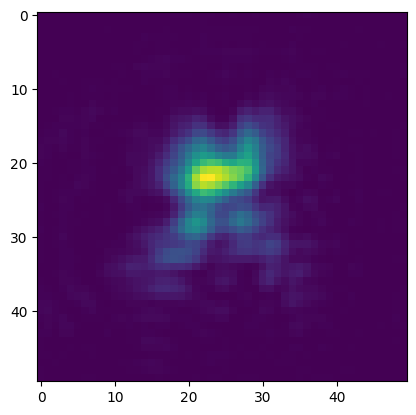

In [75]:
x0, y0 = 760, 426
window = 50
img0 = img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2]
plt.imshow(img0)

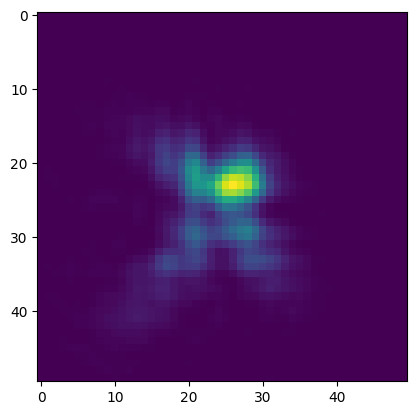

In [85]:
x1, y1 = 954, 417
window = 50
img1 = img_mean[y1-window//2:y1+window//2, x1-window//2:x1+window//2]
plt.imshow(img1)

#### Reduce Exposure

In [90]:
thorcam.set_exposure_time(0.005)

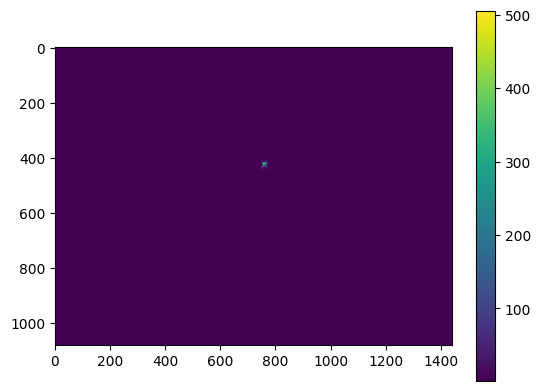

In [91]:
grating = binary_grating(16, 255)
slm.update_mask(grating)

thorcam.setup_acquisition(nframes=10)
thorcam.start_acquisition()
imgs = thorcam.acquire_n_frames(nframes=10)
img_mean = imgs.mean(axis=0)
plt.imshow(img_mean)
plt.colorbar()

#### Checking Stability

In [93]:
import time

In [95]:
I0_list = []
t_list = []
t0 = time.time()
for _ in range(100):
    thorcam.setup_acquisition(nframes=1)
    thorcam.start_acquisition()
    imgs = thorcam.acquire_n_frames(nframes=1)
    img_mean = imgs.mean(axis=0)
    
    I0 = img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2].sum()
    I0_list.append(I0)
    t_list.append(time.time() - t0)
    time.sleep(1)
    print(f"Time: {time.time() - t0:.2f} | Intensity: {I0:.2f}")

Time: 1.94 | Intensity: 68924.00
Time: 3.88 | Intensity: 69010.00
Time: 5.80 | Intensity: 68355.00
Time: 7.73 | Intensity: 69358.00
Time: 9.67 | Intensity: 68686.00
Time: 11.59 | Intensity: 68718.00
Time: 13.52 | Intensity: 69360.00
Time: 15.45 | Intensity: 69118.00
Time: 17.38 | Intensity: 68878.00
Time: 19.31 | Intensity: 69004.00
Time: 21.25 | Intensity: 69220.00
Time: 23.18 | Intensity: 69240.00
Time: 25.11 | Intensity: 69435.00
Time: 27.03 | Intensity: 69651.00
Time: 28.97 | Intensity: 69656.00
Time: 30.90 | Intensity: 69777.00
Time: 32.82 | Intensity: 70014.00
Time: 34.75 | Intensity: 69708.00
Time: 36.69 | Intensity: 70360.00
Time: 38.62 | Intensity: 69338.00
Time: 40.56 | Intensity: 69487.00
Time: 42.49 | Intensity: 69495.00
Time: 44.42 | Intensity: 69222.00
Time: 46.35 | Intensity: 69668.00
Time: 48.28 | Intensity: 69280.00
Time: 50.22 | Intensity: 69549.00
Time: 52.15 | Intensity: 69259.00
Time: 54.08 | Intensity: 69222.00
Time: 56.00 | Intensity: 69664.00
Time: 57.92 | Inten

Text(0, 0.5, '0th Order Intensity (a.u.)')

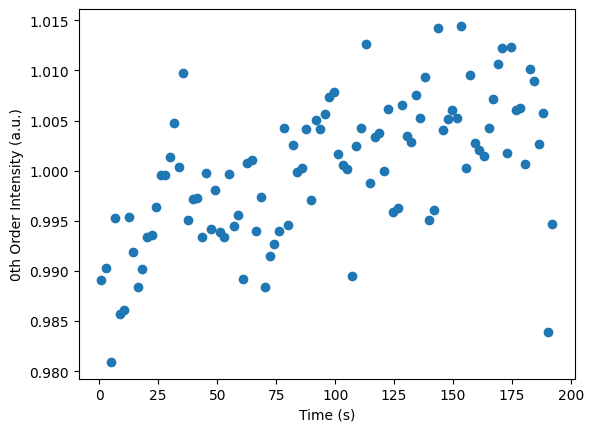

In [97]:
I0_array = np.array(I0_list)
plt.scatter(t_list, I0_array/I0_array.mean())
plt.xlabel("Time (s)")
plt.ylabel("0th Order Intensity (a.u.)")

### Calibration Scan

In [98]:
depths = np.arange(256, dtype=np.uint8)[::-1]
I0_list = []
I1_list = []

for depth in depths:
    grating = binary_grating(16, depth)
    slm.update_mask(grating)
    time.sleep(0.1)
    thorcam.setup_acquisition(nframes=3)
    thorcam.start_acquisition()
    imgs = thorcam.acquire_n_frames(nframes=3)
    img_mean = imgs.mean(axis=0)
    I0 = img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2].sum()
    I1 = img_mean[y1-window//2:y1+window//2, x1-window//2:x1+window//2].sum()
    I0_list.append(I0)
    I1_list.append(I1)

    print(f"Secondary Gray Value: {depth} | Depth: {255-depth} | 0th Order Intensity: {I0:.1f} | 1st Order Intensity: {I1:.1f}")

Secondary Gray Value: 255 | Depth: 0 | 0th Order Intensity: 68355.7 | 1st Order Intensity: 2547.7
Secondary Gray Value: 254 | Depth: 1 | 0th Order Intensity: 69593.7 | 1st Order Intensity: 2550.0
Secondary Gray Value: 253 | Depth: 2 | 0th Order Intensity: 69544.0 | 1st Order Intensity: 2544.0
Secondary Gray Value: 252 | Depth: 3 | 0th Order Intensity: 69052.3 | 1st Order Intensity: 2544.0
Secondary Gray Value: 251 | Depth: 4 | 0th Order Intensity: 69112.0 | 1st Order Intensity: 2542.3
Secondary Gray Value: 250 | Depth: 5 | 0th Order Intensity: 68474.7 | 1st Order Intensity: 2547.0
Secondary Gray Value: 249 | Depth: 6 | 0th Order Intensity: 68185.3 | 1st Order Intensity: 2548.7
Secondary Gray Value: 248 | Depth: 7 | 0th Order Intensity: 68940.0 | 1st Order Intensity: 2546.0
Secondary Gray Value: 247 | Depth: 8 | 0th Order Intensity: 68326.7 | 1st Order Intensity: 2543.7
Secondary Gray Value: 246 | Depth: 9 | 0th Order Intensity: 68920.0 | 1st Order Intensity: 2543.3
Secondary Gray Value

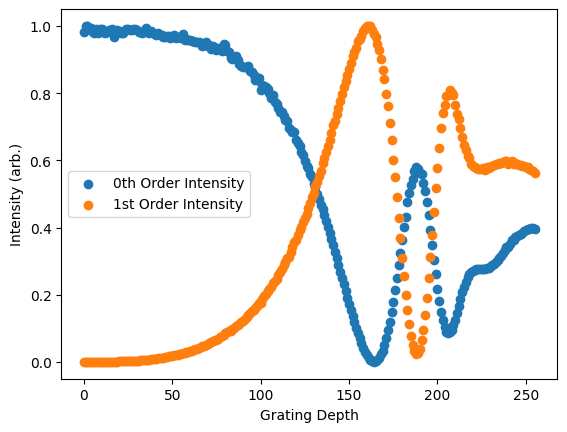

In [100]:
I0_array = np.array(I0_list)
I1_array = np.array(I1_list)

plt.scatter(depths[::-1], normalise(I0_array), label='0th Order Intensity')
plt.scatter(depths[::-1], normalise(I1_array), label='1st Order Intensity')
plt.xlabel('Grating Depth')
plt.ylabel('Intensity (arb.)')
plt.legend()
plt.show()

In [102]:
import numpy as np
import pandas as pd

# save depths[::-1] and normalise(I1_array) to CSV with no header, grey: 8-bit grey levels (0-255); intensity: normalised intensity (0-1), same length
df = pd.DataFrame({"grey_level": np.asarray(depths[::-1], dtype=np.uint8),
                   "norm_intensity": np.asarray(normalise(I1_array), dtype=float)})

df.to_csv("C:\\Program Files\\Meadowlark Optics\\Blink Plus\\Cal Kit\\Raw0.csv", index=False, float_format="%.6g")

In [103]:
slm.close()

SLM 1 closed.


### Verify LUT File

In [104]:
slm : SLM = SLM(lut_file="C:\\Program Files\\Meadowlark Optics\\Blink Plus\\LUT Files\\slm_40deg_852.lut")

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.462 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\slm_40deg_852.lut"


In [105]:
depths = np.arange(256, dtype=np.uint8)[::-1]
I0_list = []
I1_list = []

for depth in depths:
    grating = binary_grating(16, depth)
    slm.update_mask(grating)
    time.sleep(0.1)
    thorcam.setup_acquisition(nframes=3)
    thorcam.start_acquisition()
    imgs = thorcam.acquire_n_frames(nframes=3)
    img_mean = imgs.mean(axis=0)
    I0 = img_mean[y0-window//2:y0+window//2, x0-window//2:x0+window//2].sum()
    I1 = img_mean[y1-window//2:y1+window//2, x1-window//2:x1+window//2].sum()
    I0_list.append(I0)
    I1_list.append(I1)

    print(f"Secondary Gray Value: {depth} | Depth: {255-depth} | 0th Order Intensity: {I0:.1f} | 1st Order Intensity: {I1:.1f}")

Secondary Gray Value: 255 | Depth: 0 | 0th Order Intensity: 70549.7 | 1st Order Intensity: 2549.0
Secondary Gray Value: 254 | Depth: 1 | 0th Order Intensity: 70460.0 | 1st Order Intensity: 2549.7
Secondary Gray Value: 253 | Depth: 2 | 0th Order Intensity: 69531.0 | 1st Order Intensity: 2565.0
Secondary Gray Value: 252 | Depth: 3 | 0th Order Intensity: 70787.3 | 1st Order Intensity: 2579.0
Secondary Gray Value: 251 | Depth: 4 | 0th Order Intensity: 69661.7 | 1st Order Intensity: 2605.0
Secondary Gray Value: 250 | Depth: 5 | 0th Order Intensity: 69209.3 | 1st Order Intensity: 2628.0
Secondary Gray Value: 249 | Depth: 6 | 0th Order Intensity: 69525.0 | 1st Order Intensity: 2682.3
Secondary Gray Value: 248 | Depth: 7 | 0th Order Intensity: 68551.0 | 1st Order Intensity: 2731.0
Secondary Gray Value: 247 | Depth: 8 | 0th Order Intensity: 68911.0 | 1st Order Intensity: 2800.0
Secondary Gray Value: 246 | Depth: 9 | 0th Order Intensity: 68927.7 | 1st Order Intensity: 2855.7
Secondary Gray Value

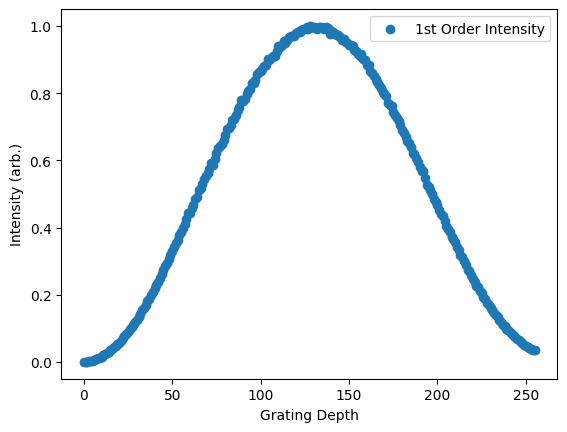

In [108]:
I0_array = np.array(I0_list)
I1_array = np.array(I1_list)

#plt.scatter(depths[::-1], normalise(I0_array), label='0th Order Intensity')
plt.scatter(depths[::-1], normalise(I1_array), label='1st Order Intensity')
plt.xlabel('Grating Depth')
plt.ylabel('Intensity (arb.)')
plt.legend()
plt.show()

In [109]:
slm.close()
thorcam.close()

SLM 1 closed.
Thorlabs TLCamera - tweezercam - closed.


---

In [3]:
slm : SLM = SLM()

SLM 1 initialised: 1024x1024 @ 8-bit, serial 7120, 41.431 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\slm_40deg_852.LUT"


In [4]:
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(10.0, 0.0),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (10.0, 0.0) um


In [7]:
W1 = np.ones((10,10))
spacing_um = 5.0

w_n, theta_n, x_n1, y_n1, z_n1 = PM.generate_weighted_array(W1, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)

terms1 = [w_n, theta_n, x_n1, y_n1, z_n1]
pm_array1, terms1, _ = PM.superposition_optimization(terms1, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 10x10
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.17e-05 | Uniformity: 65.80% | Min/Max ratio: 0.074
Iteration 010 | Mean-Squared Error: 1.98e-07 | Uniformity: 95.55% | Min/Max ratio: 0.821
Iteration 020 | Mean-Squared Error: 2.58e-08 | Uniformity: 98.39% | Min/Max ratio: 0.926
Iteration 030 | Mean-Squared Error: 1.24e-08 | Uniformity: 98.89% | Min/Max ratio: 0.946
Iteration 040 | Mean-Squared Error: 1.15e-08 | Uniformity: 98.93% | Min/Max ratio: 0.941
Iteration 050 | Mean-Squared Error: 3.77e-09 | Uniformity: 99.39% | Min/Max ratio: 0.972
Iteration 060 | Mean-Squared Error: 1.47e-09 | Uniformity: 99.62% | Min/Max ratio: 0.981
Iteration 070 | Mean-Squared Error: 2.03e-09 | Uniformity: 99.55% | Min/Max ratio: 0.980
Iteration 080 | Mean-Squared Error: 2.08e-09 | Uniformity: 99.54% | Min/Max ratio: 0.979
Iteration 090 | Mean-Squared Error: 2.08e-09 | Uniformity: 99.54% | Min/Max ratio: 0.980


In [8]:
pm_composite = PM.superimpose([pm_array1, PM.fresnel, PM.blaze])
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite).get()
slm.update_mask(pm_composite_uint8)

In [9]:
slm.close()

SLM 1 closed.
